In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import seaborn as sns;sns.set()
from scipy.stats import mode

## 7.2 Problem Setting

In this exercise, we'll look at two different datasets. First, we'll use clustering to segment the customers of a shopping mall. After that, we'll revisit the wine dataset from the decision trees chapter and find out whether clustering can also be used to predict a value.

The mall customers dataset contains data about, you guessed it, mall customers. For each customer, we know their gender, age, annual income (in thousands of dollars) and a spending score between 1 and 100. We want to find groups of customers with similar spending behavior, so that we can target our advertisements to each group.

### Data Understanding: Key Points to Consider

When working with the mall customers data, keep the following in mind:

1. **Feature Understanding**
   - `CustomerID`: unique identifier (not useful for clustering)
   - `Gender`: categorical variable (needs encoding)
   - `Age`: age of the customer in years
   - `Annual Income`: annual income of the customer in thousands of dollars
   - `Spending Score`: score between 1 and 100 that the mall assigned to the customer, based on their spending behavior

2. **Business Context**
   - Retail analytics scenario
   - Goal: group customers for targeted marketing
   - Common patterns might include:
     * High income, low spending (savers)
     * High income, high spending (prime customers)
     * Low income, high spending (enthusiastic spenders)
     * Low income, low spending (budget-conscious customers)

3. **Data Quality Considerations**
   - Check for missing values
   - Look for outliers
   - Consider the relationships between features

This understanding will guide our preprocessing and modeling decisions.

## 7.3 Part 1: Mall Customer Segmentation

As always, let's have a look at the data first.

In [2]:
df = pd.read_csv("/Users/mohammedsadmanuddin/data science fund/kMeans/Mall_Customers.csv",sep=",")
df.head()

,CustomerID,Gender,Age,Annual Income,Spending Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


##### Question 1: Try to plot a heatmap to further explore the data. Do you encounter any errors? Why does this happen? How can you solve this using a method we've already seen in previous chapters?

**Hint**: Think about what type of data a correlation matrix can work with and what the `Gender` column contains. Encode males as **0** and females as **1**.

In [3]:
df['Gender'] = df['Gender'].map({'Male':0,'Female':1})
df.head()

,CustomerID,Gender,Age,Annual Income,Spending Score
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40


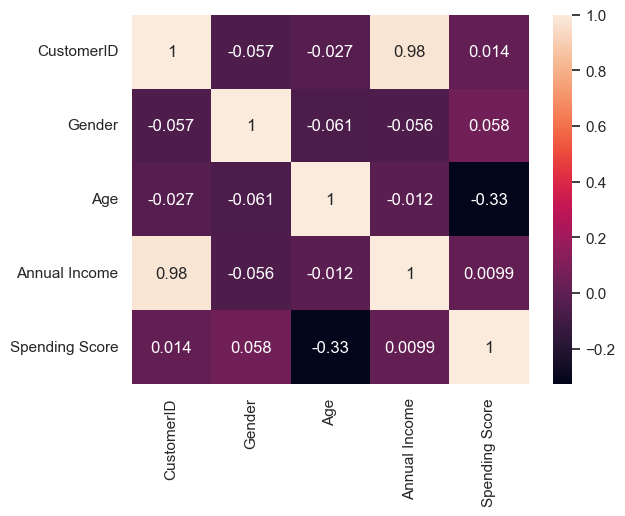

In [4]:
corr = df.corr()
sns.heatmap(corr,annot=True)
plt.show()

**Explain the error you encountered and how to solve it:**
the dataset has a column gender which contains male and female...but a correlation needs numerical value...
so i encoded the gender (male=0 and female 1)...and then we got the correlation

##### Question 2: Do you notice any strange or unexpected relation? Can you think of why this is? Is it pure chance or is there more going on?

**Your analysis:**
the most strange relationship here is customerid vs annual income which is .98 and age vs spending score
the customerid makes no sense here as it is only just an identification number...so in our upcoming model we should exclude the id column and focus on only in age,annual income,spending score and gender.

##### Question 3: We want to visualize our clusters in a simple 2D scatter plot, which can only show two variables. That's why we'll cluster on two columns at a time. Since we're interested in spending behavior, `Spending Score` will always be one of them. Pick a second column and use the elbow method to find the best value for k.

**Note**: `Age`, `Annual Income` and `Spending Score` all have values in the same range (between about 1 and 140), so we don't need to scale them first.

**Which column did you pick and why?**

i will choose annual income...by this i can understand the customer based on their income and with that income how much they want to spend...also this can help identify different customer groups like grp with high income low spend,high income high spend,low income low spend etc

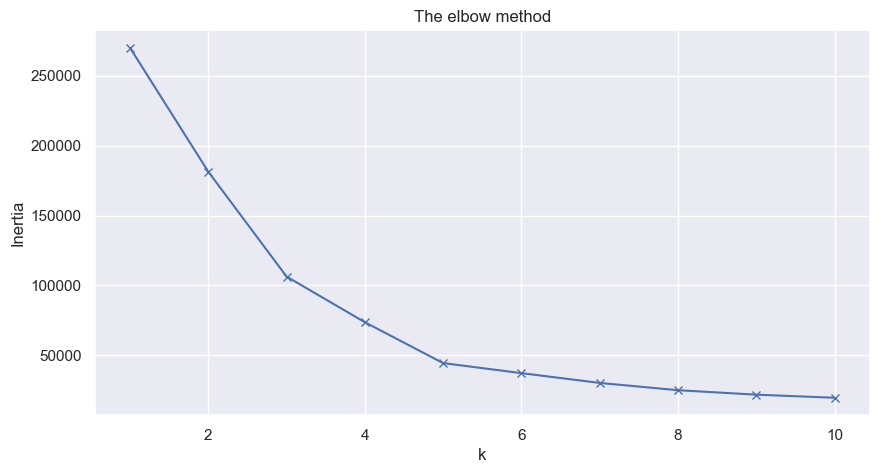

In [5]:
X = df[["Annual Income","Spending Score"]]
inertias = []
k_blobs = range(1,11)
for i in k_blobs:
    model = KMeans(n_clusters=i,random_state=0,n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)
plt.figure(figsize=(10,5))
plt.plot(k_blobs,inertias,'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('The elbow method')
plt.show()

From the graph it can be seen that from 1-4 the inertias decreased largely...but when k is 5 it started to flattening and from that the improvement become relatively small...so k 5 is the best choice

##### Question 4: Plot a graph showing the `Spending Score` as a function of the column you picked. Make sure you can visualize each individual cluster and its centroid.

In [6]:
kMeans_model = KMeans(n_clusters=5,random_state=0,n_init=10)
kMeans_predict = kMeans_model.fit_predict(X)
print(kMeans_predict)

[3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3
 4 3 4 3 4 3 0 3 4 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 2 1 0 1 2 1 2 1 0 1 2 1 2 1 2 1 2 1 0 1 2 1 2 1
 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2
 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1]


Here are the predicted values of our kmeans model where customer 1 belongs to cluster 3 and customer 2 to cluster 4 and so on

In [7]:
centroids = kMeans_model.cluster_centers_
print(centroids)

[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]
 [26.30434783 20.91304348]
 [25.72727273 79.36363636]]


From the code above we can see that:
- in cluster 0 the annual income is 55 and spending score is 49
- in cluster 1 the annual income is 86 and spending score is 82
- in cluster 2 the annual income is 88 and spending score is 17
- in cluster 3 the annual income is 26 and spending score is 20
- in cluster 4 the annual income is 25 and spending score is 79

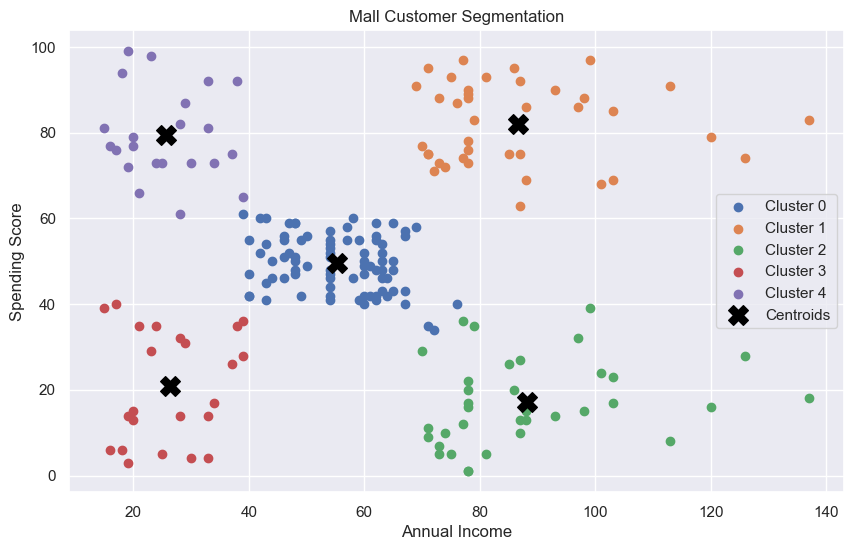

In [8]:
plt.figure(figsize=(10, 6))
for i in range(5):
    plt.scatter(X.iloc[kMeans_predict == i, 0],X.iloc[kMeans_predict == i, 1],label=f'Cluster {i}')
    
plt.scatter(centroids[:, 0],centroids[:, 1],marker='X',s=200,color='black',label='Centroids')

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Mall Customer Segmentation')
plt.legend()
plt.show()

**Your analysis:**
From the graph we can clearly see the clusters and its centorids
- cluster 0(avg income,avg spending)
- cluster 1(high income,high spending)
- cluster 2(high income,low spending)
- cluster 3(low income,low spending)
- cluster 4(low income,high spending)

##### Question 5: You've explored the relation of one column with `Spending Score`, now explore the other columns. Are there any more insights to be revealed?

###### Clustering on Gender

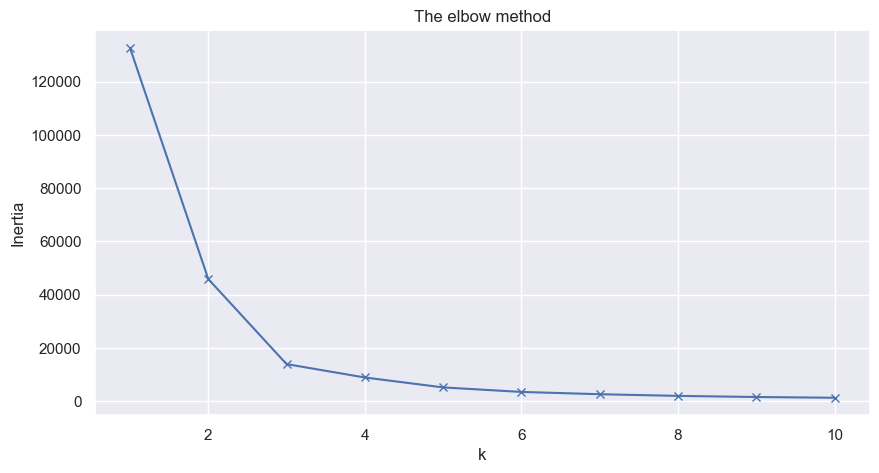

[0 1 2 1 0 1 2 1 2 1 2 1 2 1 2 1 0 1 2 1 0 1 2 1 2 1 0 0 2 1 2 1 2 1 2 1 2
 1 2 1 0 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 2 1 0 1 2 1 2 1 0 1 2 1 2 1 2 1 2 1 0 1 2 1 0 1
 2 1 2 1 2 1 2 1 2 1 2 1 0 1 2 1 2 1 2 1 2 0 2 1 2 1 2 1 2 1 2 1 0 1 2 1 0
 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1]
[[ 0.58947368 48.35789474]
 [ 0.56896552 82.06896552]
 [ 0.4893617  14.59574468]]


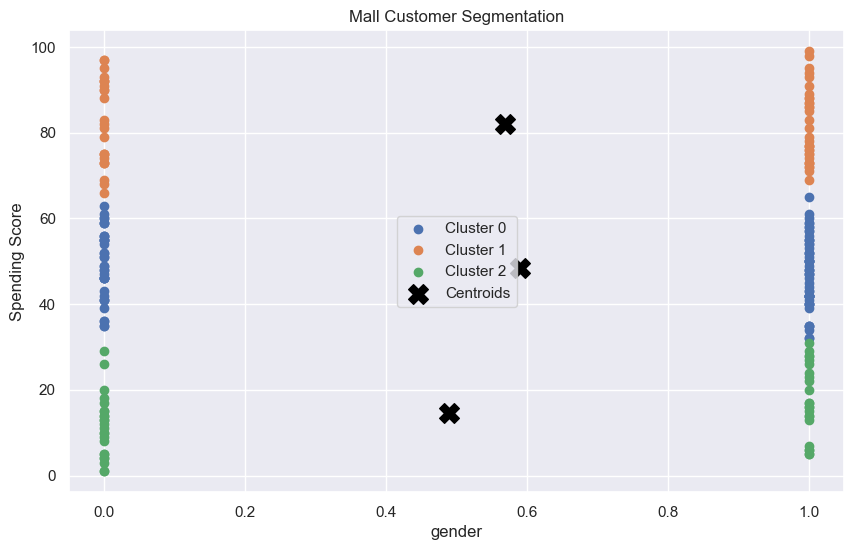

In [9]:
X = df[["Gender","Spending Score"]]
inertias = []
k_blobs = range(1,11)
for i in k_blobs:
    model = KMeans(n_clusters=i,random_state=0,n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)
plt.figure(figsize=(10,5))
plt.plot(k_blobs,inertias,'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('The elbow method')
plt.show()
kMeans_model = KMeans(n_clusters=3,random_state=0,n_init=10)
kMeans_predict = kMeans_model.fit_predict(X)
print(kMeans_predict)
centroids = kMeans_model.cluster_centers_
print(centroids)
plt.figure(figsize=(10, 6))
for i in range(3):
    plt.scatter(X.iloc[kMeans_predict == i, 0],X.iloc[kMeans_predict == i, 1],label=f'Cluster {i}')
    
plt.scatter(centroids[:, 0],centroids[:, 1],marker='X',s=200,color='black',label='Centroids')

plt.xlabel('gender')
plt.ylabel('Spending Score')
plt.title('Mall Customer Segmentation')
plt.legend()
plt.show()

**Your analysis:**
This makes no sense...kMeans is not particularly suitable for gender even if encode it to 0 and 1...as we know gender is categorical...and here spending scores dominates
But the best k here is 3

###### Clustering on Annual Income or age

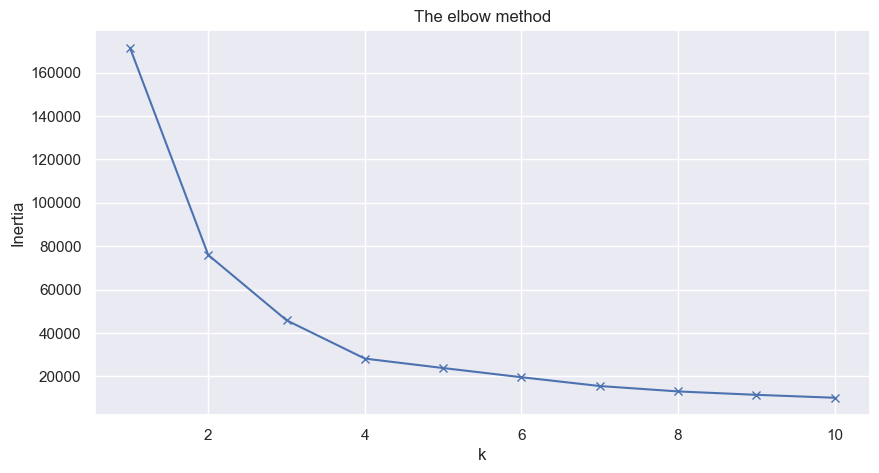

[3 1 2 1 3 1 2 1 2 1 2 1 2 1 2 1 3 3 2 1 3 1 2 1 2 1 2 3 2 1 2 1 2 1 2 1 2
 1 2 1 0 1 0 3 2 3 0 3 3 3 0 3 3 0 0 0 0 0 3 0 0 3 0 0 0 3 0 0 3 3 0 0 0 0
 0 3 0 3 3 0 0 3 0 0 3 0 0 3 3 0 0 3 0 3 3 3 0 3 0 3 3 0 0 3 0 3 0 0 0 0 0
 3 3 3 3 3 0 0 0 0 3 3 3 1 3 1 0 1 2 1 2 1 3 1 2 1 2 1 2 1 2 1 3 1 2 1 0 1
 2 1 2 1 2 1 2 1 2 1 2 1 0 1 2 1 2 1 2 1 2 3 2 1 2 1 2 1 2 1 2 1 2 1 2 1 3
 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1]
[[55.70833333 48.22916667]
 [30.1754386  82.35087719]
 [43.29166667 15.02083333]
 [27.61702128 49.14893617]]


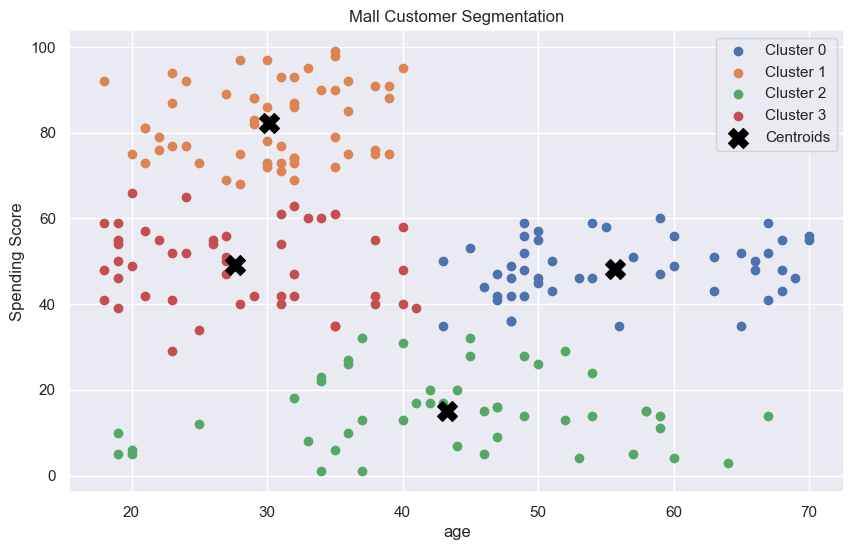

In [10]:
X = df[["Age","Spending Score"]]
inertias = []
k_blobs = range(1,11)
for i in k_blobs:
    model = KMeans(n_clusters=i,random_state=0,n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)
plt.figure(figsize=(10,5))
plt.plot(k_blobs,inertias,'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('The elbow method')
plt.show()
kMeans_model = KMeans(n_clusters=4,random_state=0,n_init=10)
kMeans_predict = kMeans_model.fit_predict(X)
print(kMeans_predict)
centroids = kMeans_model.cluster_centers_
print(centroids)
plt.figure(figsize=(10, 6))
for i in range(4):
    plt.scatter(X.iloc[kMeans_predict == i, 0],X.iloc[kMeans_predict == i, 1],label=f'Cluster {i}')
    
plt.scatter(centroids[:, 0],centroids[:, 1],marker='X',s=200,color='black',label='Centroids')

plt.xlabel('age')
plt.ylabel('Spending Score')
plt.title('Mall Customer Segmentation')
plt.legend()
plt.show()

**Your analysis:**
From the graph, we can observe that customers are grouped into different clusters based on their age and spending behaviour. Younger customers appear across different spending levels, while some older customers also show varying spending patterns. This suggests that there is no clear linear relationship between age and spending score, but K-Means helps identify groups of customers with similar characteristics.
From the graph we can clearly see the clusters and their centroids:
* Cluster 0 (older customers, average spending)
* Cluster 1 (middle-aged customers, low spending)
* Cluster 2 (younger customers, high spending)
* Cluster 3 (younger customers, average spending)
* Cluster 4 (middle-aged customers, moderate spending)

## 7.4 Part 2: Wine Quality Analysis

Now we'll apply clustering to the wine dataset, which presents different challenges:

1. **Domain Context**
   - Each wine has 11 chemical properties (acidity, sugar, alcohol, ...)
   - Each wine also received a quality score from experts (between 3 and 8 in this dataset)

2. **Technical Considerations**
   - More features than in the mall dataset (11 instead of 4)
   - Features measured on very different scales (for example density between 0.99 and 1.00, but total sulfur dioxide between 6 and 289)

3. **Analysis Goals**
   - Find natural groupings of wines
   - Find out whether these groupings are related to quality
   - Test whether clustering can be used to *predict* the quality

This exercise shows how clustering can (or cannot) reveal patterns in more complex, multi-dimensional data.

In [11]:
df_wine = pd.read_csv("/Users/mohammedsadmanuddin/data science fund/kMeans/Wine (1).csv",sep=",")
df_wine=df_wine.drop(columns=["Id"])
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


##### Question 8: We want to explore how each chemical property relates to the quality of the wine. For each of the 11 features, cluster the pair (feature, `quality`): find the best value of k with the elbow method and plot the clusters. What can you learn from this?

**Important**: k-means is based on distances. When one column has much larger values than the other, it dominates the distance calculation and the clusters would only follow that column. For example, `total sulfur dioxide` goes from 6 to 289, while `quality` only goes from 3 to 8. That's why we first **standardize** both columns with scikit-learn's `StandardScaler`: it rescales every column so that it has a mean of 0 and a standard deviation of 1. After that, both columns count equally in the distance calculation.

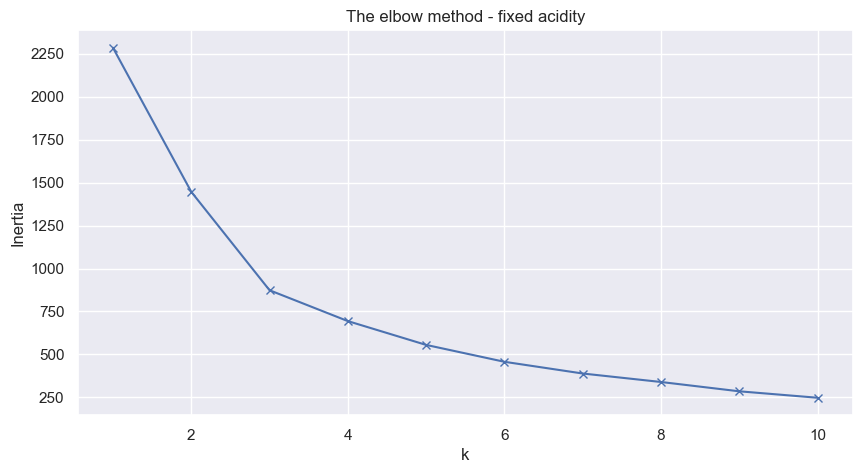

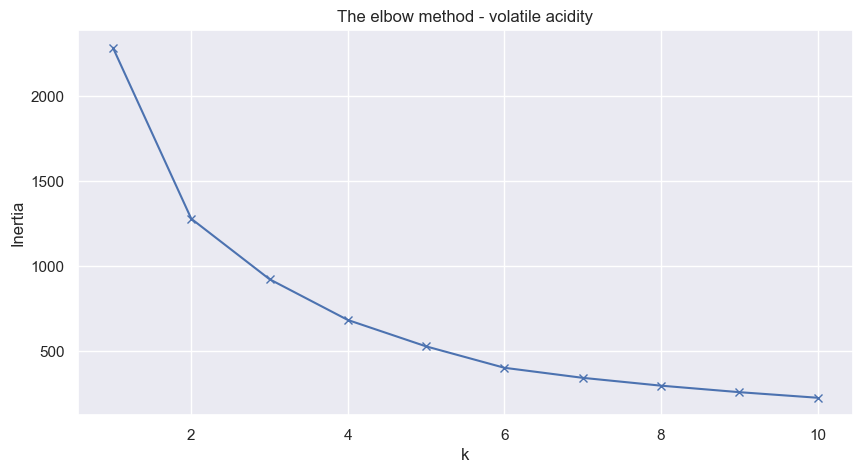

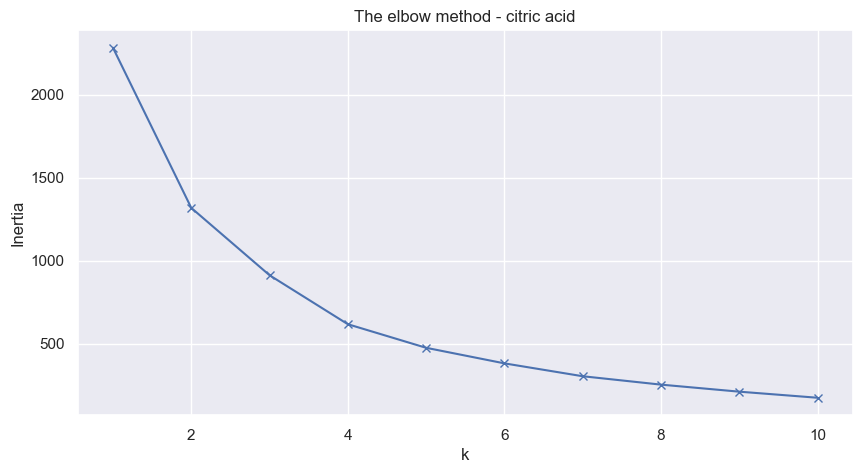

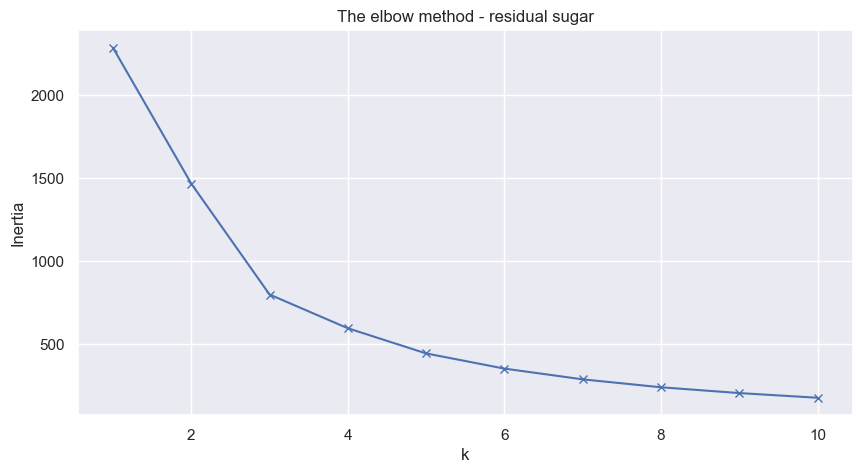

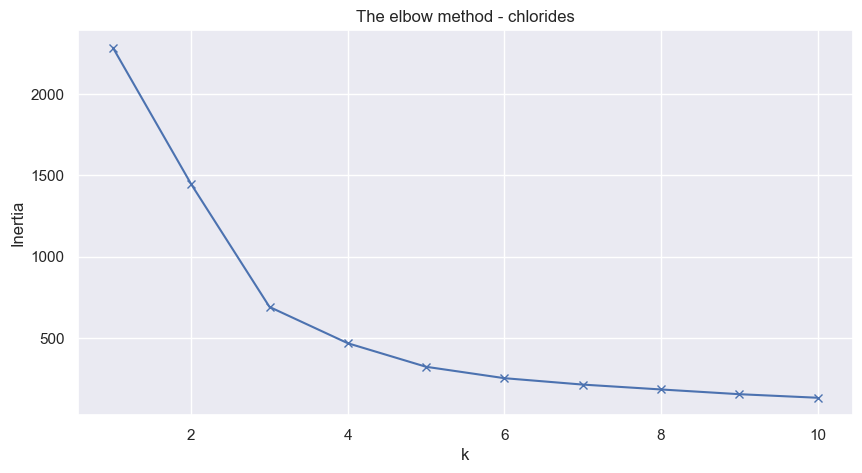

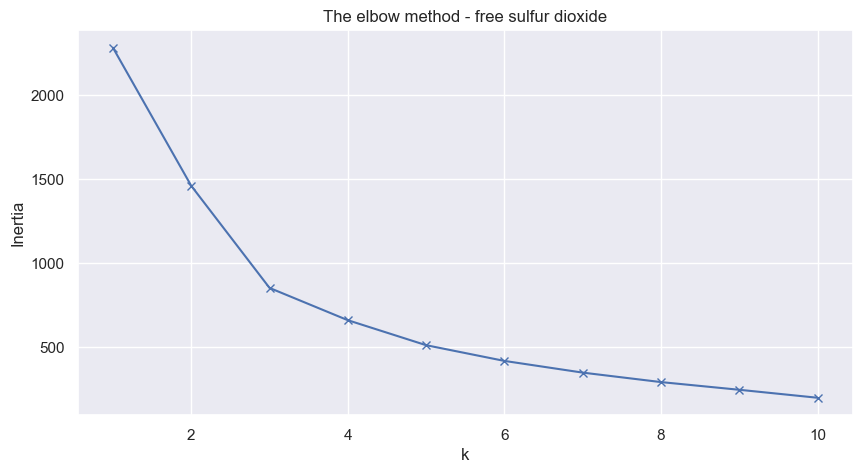

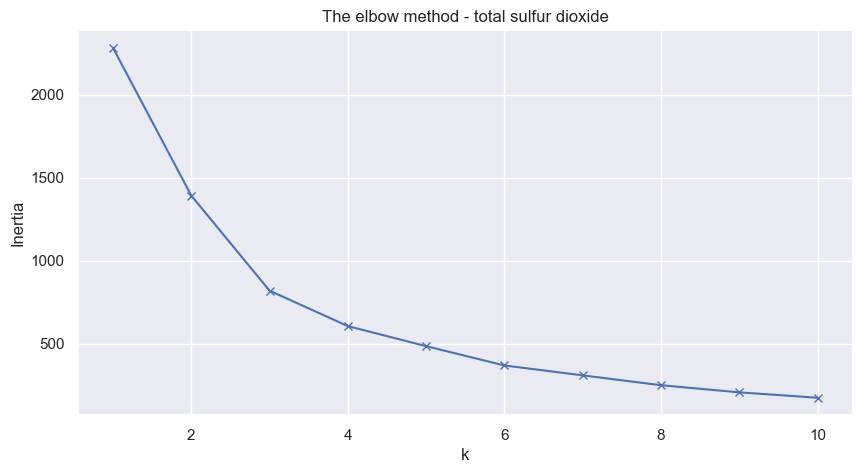

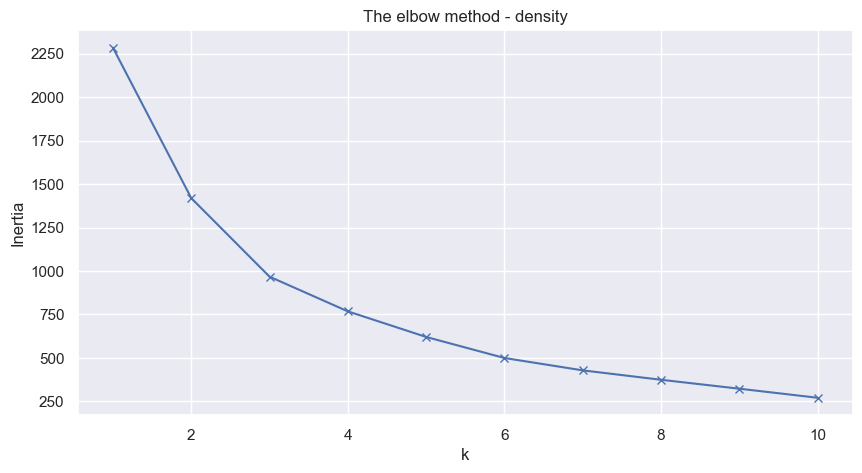

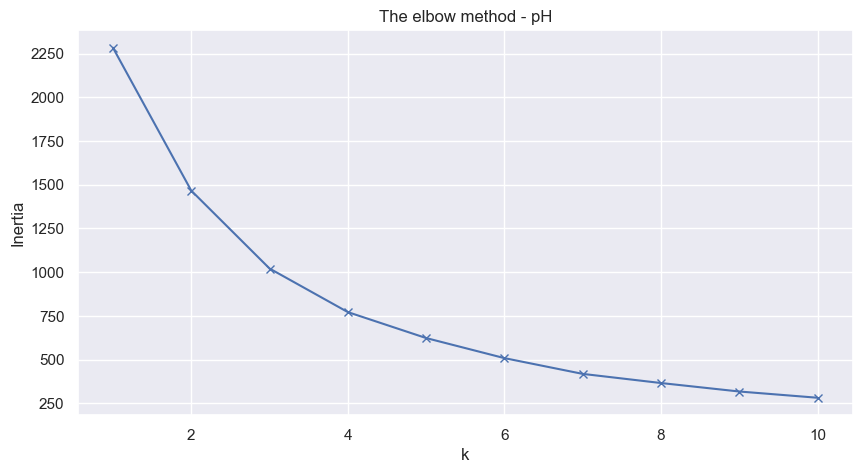

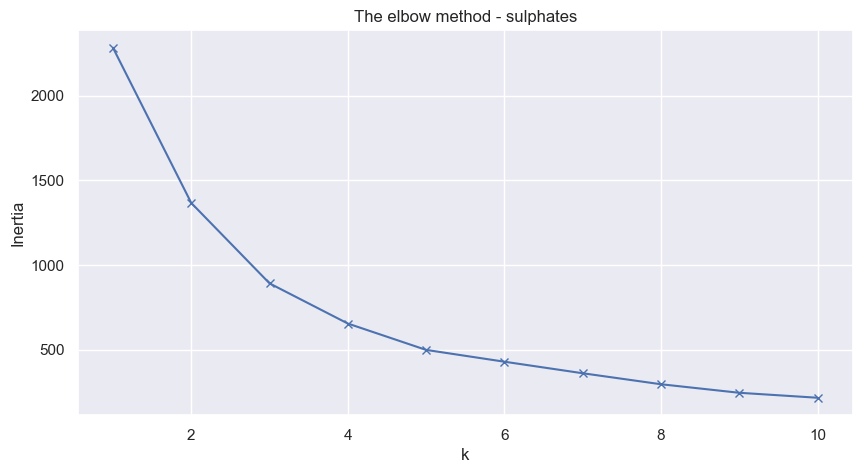

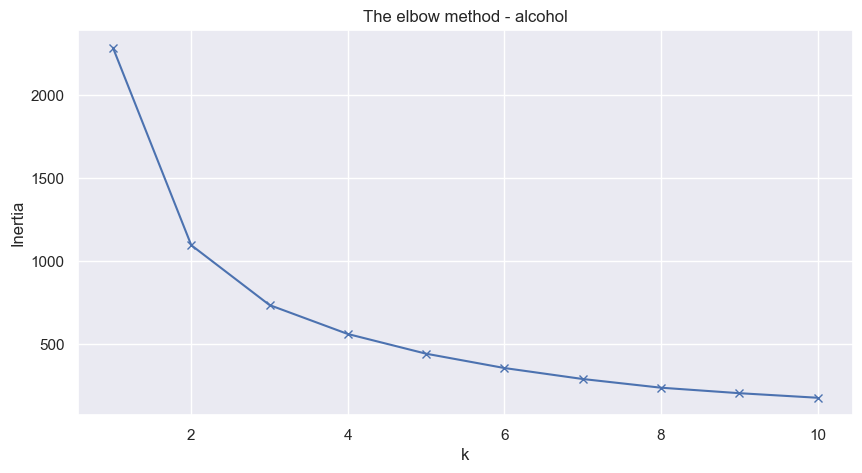

In [12]:
from sklearn.preprocessing import StandardScaler
features = ["fixed acidity","volatile acidity","citric acid","residual sugar","chlorides","free sulfur dioxide","total sulfur dioxide","density","pH","sulphates","alcohol"]
for feature in features:
    X = df_wine[[feature,"quality"]]
    scaler = StandardScaler()
    X_scale = scaler.fit_transform(X)
    inertias = []
    k_blobs = range(1,11)
    for i in k_blobs:
        model = KMeans(n_clusters=i,random_state=0,n_init=10)
        model.fit(X_scale)
        inertias.append(model.inertia_)
    plt.figure(figsize=(10,5))
    plt.plot(k_blobs,inertias,'bx-')
    plt.xlabel('k')
    plt.ylabel('Inertia')
    plt.title(f'The elbow method - {feature}')
    plt.show()
    

**Your analysis:**
from the graphs of elbow method..i can say the best k for each features are:
    fixed acidity=3
    volatile acidity=4
    citric acid=4
    residual sugar=3
    chlorides=4
    free sulfur dioxide=3
    total sulfur dioxide=4
    density=4
    pH=4
    sulphates=5
    alcohol=4

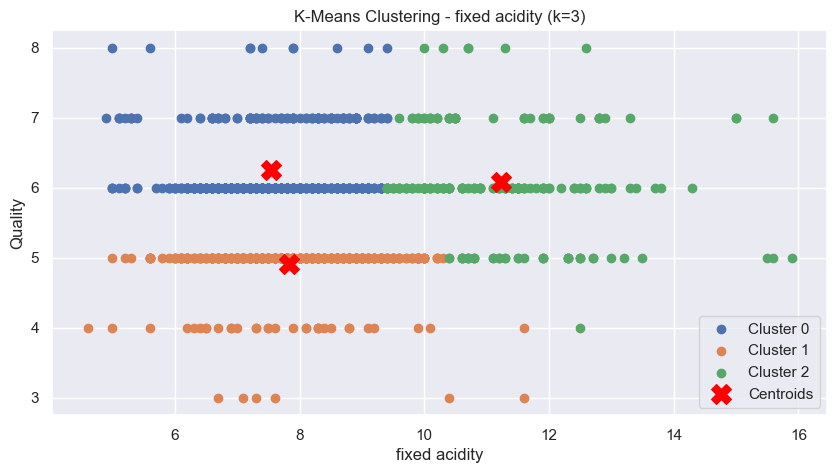

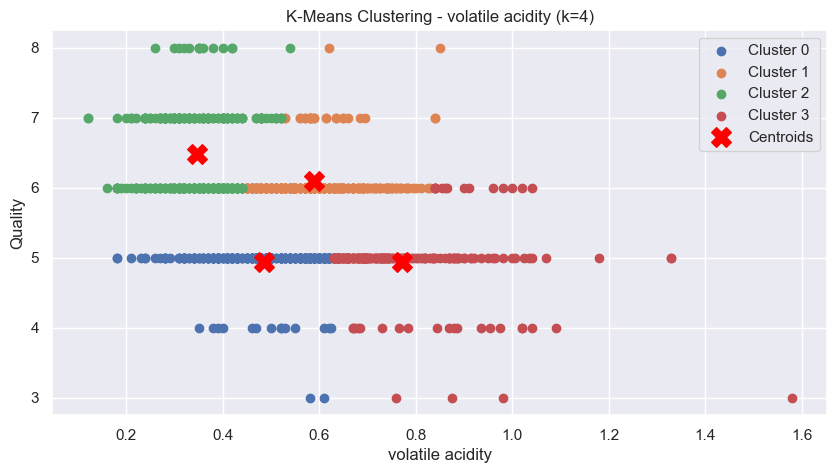

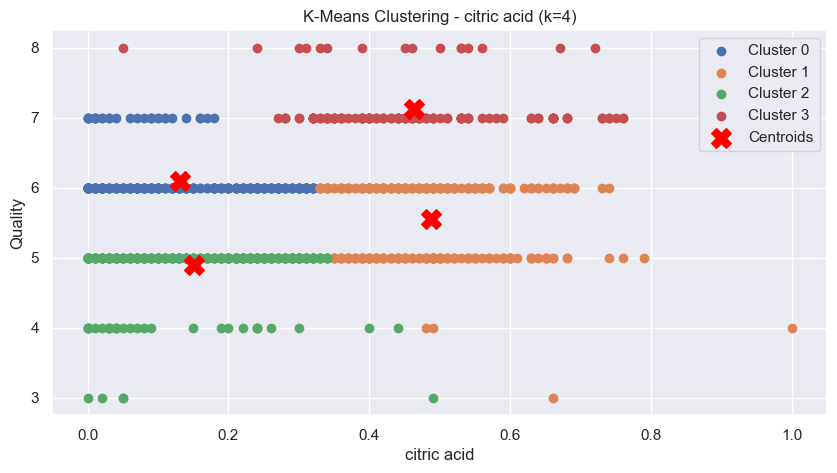

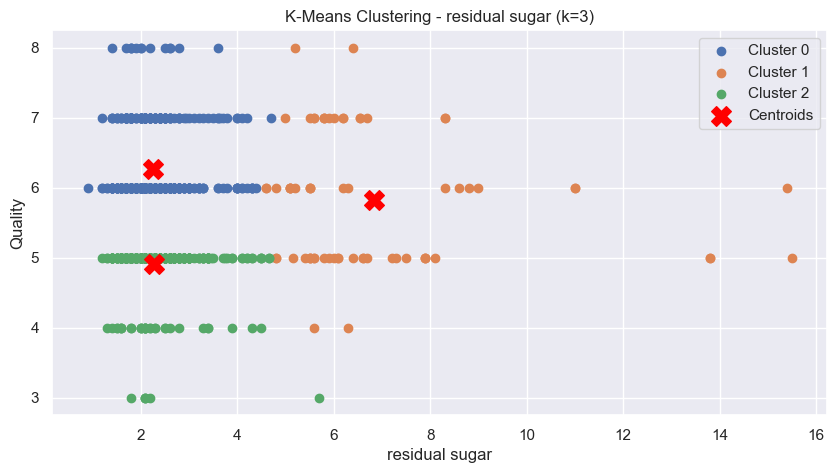

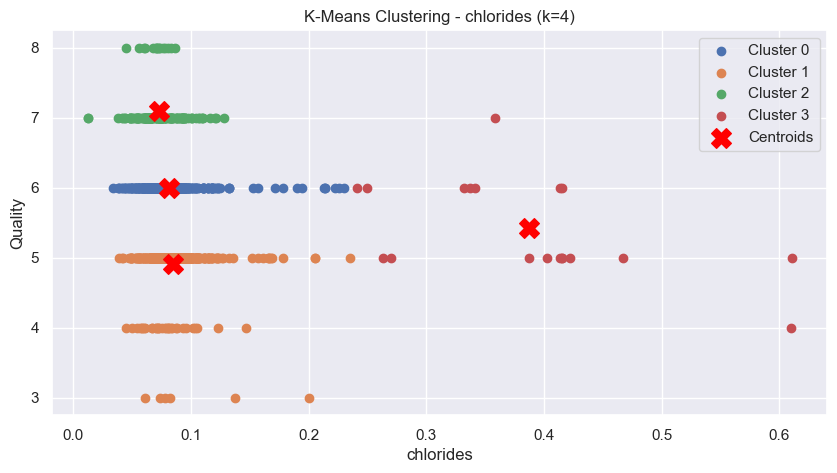

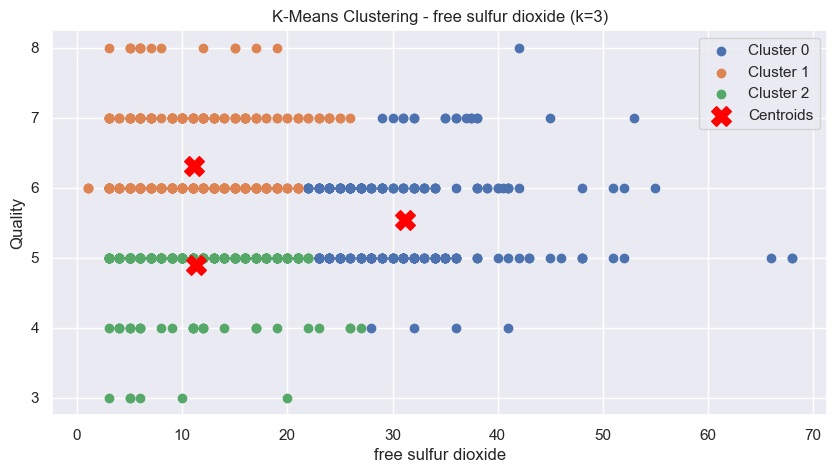

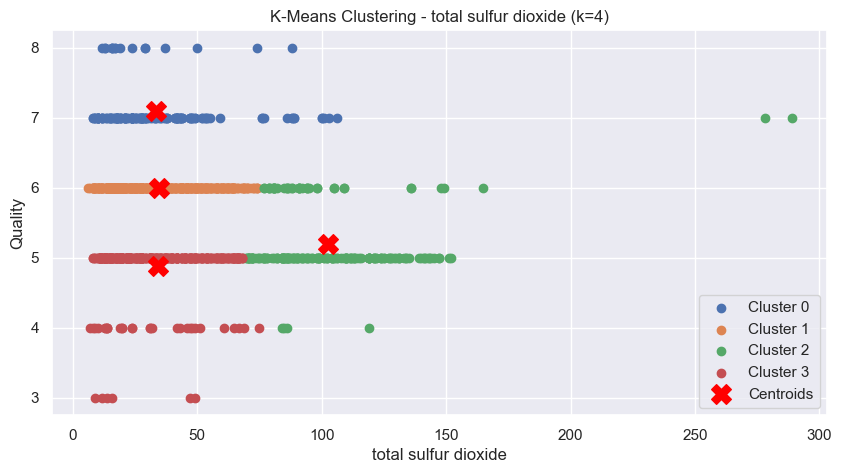

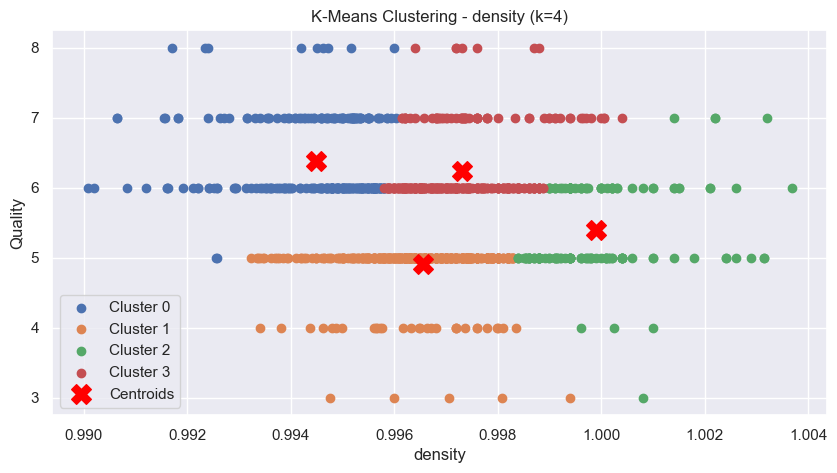

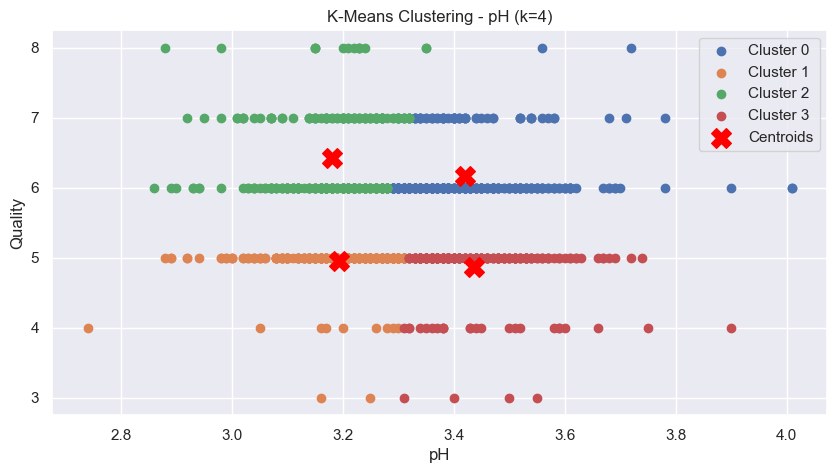

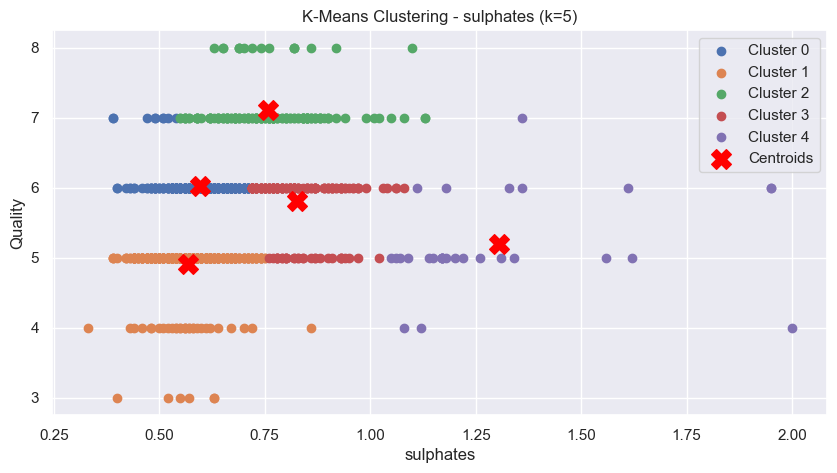

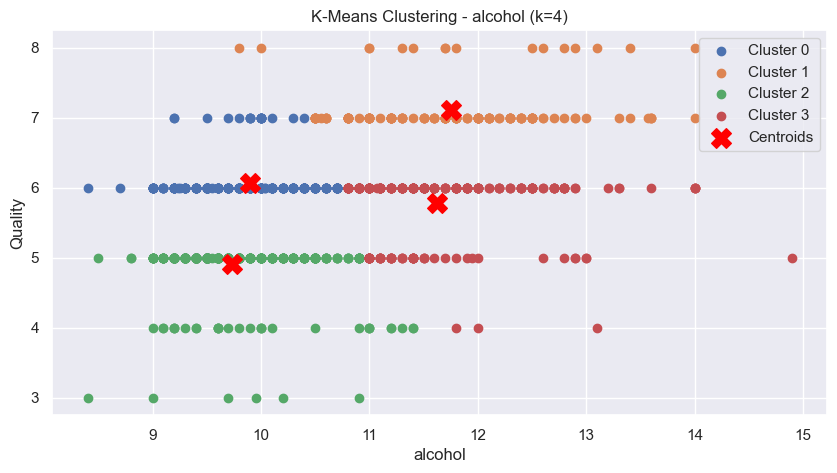

In [13]:
best_k = {"fixed acidity": 3,"volatile acidity": 4,"citric acid": 4,"residual sugar": 3,"chlorides": 4,"free sulfur dioxide": 3,"total sulfur dioxide": 4,"density": 4,"pH": 4,"sulphates": 5,"alcohol": 4}
for feature in features:
    X = df_wine[[feature,"quality"]]
    scaler = StandardScaler()
    X_scale = scaler.fit_transform(X)
    model = KMeans(n_clusters=best_k[feature],random_state=0,n_init=10)
    cluster = model.fit_predict(X_scale)
    centroids = scaler.inverse_transform(model.cluster_centers_)
    plt.figure(figsize=(10, 5))
    for i in range(best_k[feature]):
        plt.scatter(X[feature][cluster == i],X["quality"][cluster == i],label=f"Cluster {i}")
    plt.scatter(centroids[:, 0], centroids[:, 1],color="red", marker="X", s=200, label="Centroids")
    plt.xlabel(feature)
    plt.ylabel("Quality")
    plt.title(f"K-Means Clustering - {feature} (k={best_k[feature]})")
    plt.legend()
    plt.show()

##### Question 9: Try to use clustering to predict the quality of a wine. Feel free to use all columns (except `quality` itself) for this model. Think about how many clusters you would expect in this case!

**Hint**: Use the same approach as with the digits in the notebook: translate each cluster into the most common quality among its wines. Don't forget to standardize the features first.

In [14]:
features = list(df_wine.columns)
features.remove("quality")
X = df_wine[features]
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)
model = KMeans(n_clusters=6,random_state=0,n_init=10)
cluster = model.fit_predict(X_scale)
cluster_quality = {}
for i in range(6):
    cluster_quality[i] = df_wine["quality"][cluster == i].mode()[0]
predicted_quality = []
for i in cluster:
    predicted_quality.append(cluster_quality[i])
print("Cluster quality:", cluster_quality)
print("Predicted quality:", predicted_quality)
print("Actual quality:", list(df_wine["quality"]))

accuracy = sum(predicted_quality[i] == df_wine["quality"].iloc[i] for i in range(len(df_wine))) / len(df_wine)

print("Accuracy:", accuracy)

Cluster quality: {0: np.int64(5), 1: np.int64(6), 2: np.int64(6), 3: np.int64(5), 4: np.int64(6), 5: np.int64(5)}
Predicted quality: [np.int64(5), np.int64(5), np.int64(5), np.int64(6), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(6), np.int64(6), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(6), np.int64(5), np.int64(5), np.int64(5), np.int64(6), np.int64(6), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(6), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(6), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(6), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64

**Your analysis:**
* Number of clusters: 6
* Cluster quality:
- Cluster 0 → Quality 5
- Cluster 1 → Quality 6
- Cluster 2 → Quality 6
- Cluster 3 → Quality 6
- Cluster 4 → Quality 6
- Cluster 5 → Quality 5

- Accuracy: 0.5464 = 54.64%

the kmeans model achieved a very low accuracy score...which mean clustering is not very effective to predict wine quality